In [1]:
import pandas as pd

df = pd.read_csv(
    "data/WA_Fn-UseC_-HR-Employee-Attrition.csv"
)

print("\nPrimeiras linhas:")
print(df.head())

print("\nDimensões:")
print(df.shape)

print("\nInformações:")
print(df.info())

print("\nValores nulos:")
print(df.isnull().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'data/WA_Fn-UseC_-HR-Employee-Attrition.csv'

In [8]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [9]:
df.shape

(1470, 35)

In [10]:
df.columns.tolist()

['Age',
 'Attrition',
 'BusinessTravel',
 'DailyRate',
 'Department',
 'DistanceFromHome',
 'Education',
 'EducationField',
 'EmployeeCount',
 'EmployeeNumber',
 'EnvironmentSatisfaction',
 'Gender',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobRole',
 'JobSatisfaction',
 'MaritalStatus',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'Over18',
 'OverTime',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StandardHours',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager']

In [11]:
df[['Age',
    'Attrition',
    'Department',
    'JobRole',
    'MonthlyIncome',
    'OverTime']].head(10)

,Age,Attrition,Department,JobRole,MonthlyIncome,OverTime
0,41,Yes,Sales,Sales Executive,5993,Yes
1,49,No,Research & Development,Research Scientist,5130,No
2,37,Yes,Research & Development,Laboratory Technician,2090,Yes
3,33,No,Research & Development,Research Scientist,2909,Yes
4,27,No,Research & Development,Laboratory Technician,3468,No
5,32,No,Research & Development,Laboratory Technician,3068,No
6,59,No,Research & Development,Laboratory Technician,2670,Yes
7,30,No,Research & Development,Laboratory Technician,2693,No
8,38,No,Research & Development,Manufacturing Director,9526,No
9,36,No,Research & Development,Healthcare Representative,5237,No


In [12]:
df['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [13]:
turnover = (237 / 1470) * 100
print(f"Taxa de Turnover: {turnover:.2f}%")

Taxa de Turnover: 16.12%


In [14]:
turnover = (
    df['Attrition']
    .value_counts(normalize=True)['Yes']
    * 100
)

print(f"Taxa de Turnover: {turnover:.2f}%")


Taxa de Turnover: 16.12%


In [15]:
pd.crosstab(df['OverTime'], df['Attrition'])

Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


In [16]:
pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


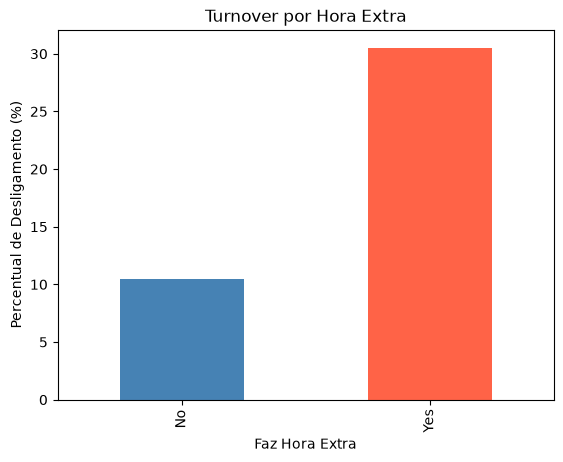

In [18]:
import matplotlib.pyplot as plt

turnover_overtime = pd.crosstab(
    df['OverTime'],
    df['Attrition'],
    normalize='index'
) * 100

turnover_overtime['Yes'].plot(
    kind='bar',
    color=['steelblue', 'tomato']
)

plt.title('Turnover por Hora Extra')
plt.xlabel('Faz Hora Extra')
plt.ylabel('Percentual de Desligamento (%)')
plt.show()

In [19]:
df.groupby('Attrition')['MonthlyIncome'].mean()

Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64

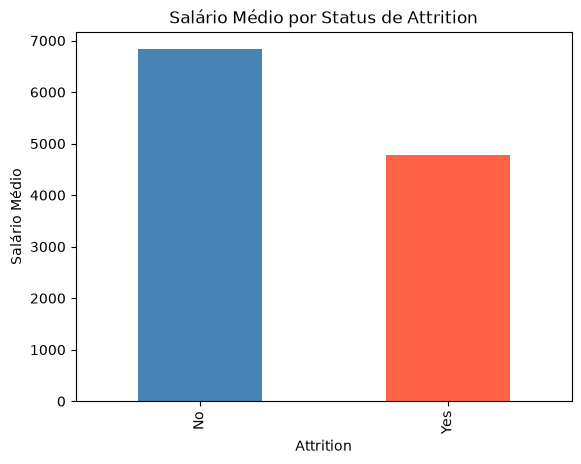

In [20]:
import matplotlib.pyplot as plt

salario_medio = df.groupby('Attrition')['MonthlyIncome'].mean()

salario_medio.plot(
    kind='bar',
    color=['steelblue', 'tomato']
)

plt.title('Salário Médio por Status de Attrition')
plt.xlabel('Attrition')
plt.ylabel('Salário Médio')
plt.show()

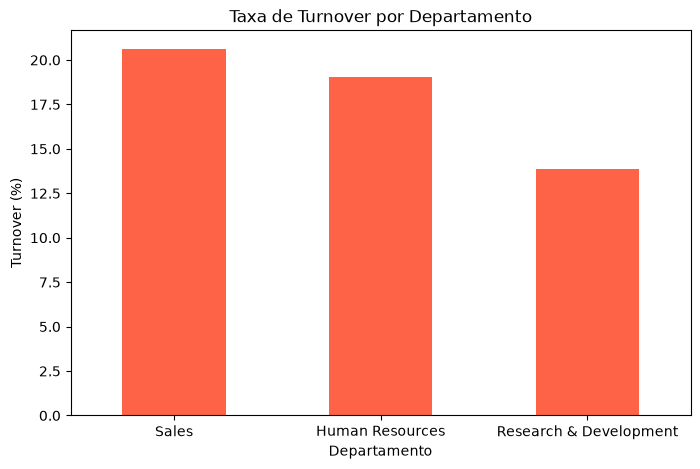

In [23]:
turnover_departamento = pd.crosstab(
    df['Department'],
    df['Attrition'],
    normalize='index'
) * 100

turnover_departamento

turnover_departamento['Yes'].sort_values(ascending=False)

turnover_departamento['Yes'] \
    .sort_values(ascending=False) \
    .plot(
        kind='bar',
        color='tomato',
        figsize=(8, 5)
    )

plt.title('Taxa de Turnover por Departamento')
plt.xlabel('Departamento')
plt.ylabel('Turnover (%)')
plt.xticks(rotation=0)
plt.show()

In [24]:
turnover_cargo = pd.crosstab(
    df['JobRole'],
    df['Attrition'],
    normalize='index'
) * 100

turnover_cargo['Yes'].sort_values(
    ascending=False
)


JobRole
Sales Representative         39.759036
Laboratory Technician        23.938224
Human Resources              23.076923
Sales Executive              17.484663
Research Scientist           16.095890
Manufacturing Director        6.896552
Healthcare Representative     6.870229
Manager                       4.901961
Research Director             2.500000
Name: Yes, dtype: float64

In [25]:
pd.crosstab(
    df['JobSatisfaction'],
    df['Attrition'],
    normalize='index'
) * 100

Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


In [26]:
pd.crosstab(
    df['WorkLifeBalance'],
    df['Attrition'],
    normalize='index'
) * 100

Attrition,No,Yes
WorkLifeBalance,,
1,68.750000,31.250000
2,83.139535,16.860465
3,85.778275,14.221725
4,82.352941,17.647059


In [27]:
import sqlite3

In [28]:
conn = sqlite3.connect("people_analytics.db")
print("Banco criado com sucesso!")

Banco criado com sucesso!


In [29]:
df.to_sql(
    "funcionarios",
    conn,
    if_exists="replace",
    index=False
)

print("Tabela criada com sucesso!")

Tabela criada com sucesso!


In [30]:
query = """
SELECT
    COUNT(*) AS total_funcionarios
FROM funcionarios;
"""

resultado = pd.read_sql_query(
    query,
    conn
)

resultado


,total_funcionarios
0,1470


In [31]:
query = """
SELECT
    ROUND(
        100.0 * SUM(
            CASE
                WHEN Attrition = 'Yes' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS turnover_percent
FROM funcionarios;
"""

pd.read_sql_query(query, conn)


,turnover_percent
0,16.12


In [32]:
query = """
SELECT
    Department,
    ROUND(
        100.0 * SUM(
            CASE
                WHEN Attrition = 'Yes' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS turnover_percent
FROM funcionarios
GROUP BY Department
ORDER BY turnover_percent DESC;
"""

pd.read_sql_query(query, conn)

,Department,turnover_percent
0,Sales,20.63
1,Human Resources,19.05
2,Research & Development,13.84


In [33]:
query = """
SELECT
    Attrition,
    ROUND(AVG(MonthlyIncome), 2) AS salario_medio
FROM funcionarios
GROUP BY Attrition;
"""

pd.read_sql_query(query, conn)

,Attrition,salario_medio
0,No,6832.74
1,Yes,4787.09


In [34]:
query = """
SELECT
    JobRole,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN Attrition = 'Yes' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS turnover_percent

FROM funcionarios

GROUP BY JobRole

ORDER BY turnover_percent DESC

LIMIT 5;
"""

pd.read_sql_query(query, conn)

,JobRole,turnover_percent
0,Sales Representative,39.76
1,Laboratory Technician,23.94
2,Human Resources,23.08
3,Sales Executive,17.48
4,Research Scientist,16.10


In [35]:
query = """
CREATE VIEW vw_turnover_departamento AS

SELECT
    Department,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN Attrition = 'Yes' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS turnover_percent

FROM funcionarios

GROUP BY Department;
"""

conn.execute(query)

print("VIEW criada com sucesso!")

VIEW criada com sucesso!


In [36]:
pd.read_sql_query(
    """
    SELECT *
    FROM vw_turnover_departamento
    ORDER BY turnover_percent DESC
    """,
    conn
)

,Department,turnover_percent
0,Sales,20.63
1,Human Resources,19.05
2,Research & Development,13.84


In [37]:
query = """
CREATE VIEW vw_turnover_cargo AS

SELECT
    JobRole,

    ROUND(
        100.0 *
        SUM(
            CASE
                WHEN Attrition = 'Yes' THEN 1
                ELSE 0
            END
        ) / COUNT(*),
        2
    ) AS turnover_percent

FROM funcionarios

GROUP BY JobRole;
"""

conn.execute(query)

print("VIEW criada!")

VIEW criada!


In [38]:
pd.read_sql_query(
    """
    SELECT *
    FROM vw_turnover_cargo
    ORDER BY turnover_percent DESC
    """,
    conn
)

,JobRole,turnover_percent
0,Sales Representative,39.76
1,Laboratory Technician,23.94
2,Human Resources,23.08
3,Sales Executive,17.48
4,Research Scientist,16.10
5,Manufacturing Director,6.90
6,Healthcare Representative,6.87
7,Manager,4.90
8,Research Director,2.50


In [39]:
query = """
CREATE VIEW vw_dashboard_executivo AS

SELECT

    COUNT(*) AS total_funcionarios,

    SUM(
        CASE
            WHEN Attrition = 'Yes'
            THEN 1
            ELSE 0
        END
    ) AS total_desligamentos,

    ROUND(
        AVG(MonthlyIncome),
        2
    ) AS salario_medio,

    ROUND(
        AVG(YearsAtCompany),
        2
    ) AS media_anos_empresa

FROM funcionarios;
"""

conn.execute(query)

print("VIEW criada!")

VIEW criada!


In [40]:
pd.read_sql_query(
    """
    SELECT *
    FROM vw_dashboard_executivo
    """,
    conn
)

,total_funcionarios,total_desligamentos,salario_medio,media_anos_empresa
0,1470,237,6502.93,7.01


In [41]:
import os

os.listdir()

['datasets',
 'people_analytics.db',
 'people_analytics.py.ipynb',
 'WA_Fn-UseC_-HR-Employee-Attrition.csv']

In [42]:
pd.read_sql_query("""
SELECT name
FROM sqlite_master
WHERE type IN ('table', 'view')
ORDER BY name;
""", conn)

,name
0,funcionarios
1,vw_dashboard_executivo
2,vw_turnover_cargo
3,vw_turnover_departamento
